# Hospital OPD Time Series Analysis & Forecasting
**Integrated Phase 1 + Phase 2 notebook**

This notebook is designed to run the complete workflow in one place:
1. Load and inspect the OPD appointment/visit data
2. Clean data and create daily total + department-wise series
3. Perform EDA, rolling statistics, weekday analysis and decomposition
4. Check stationarity with ADF/KPSS and inspect ACF/PACF
5. Train and compare classical forecasting models
6. Run a multivariate VAR model across departments
7. Optionally run TSFresh, Prophet, Darts and AutoTS (if installed)
8. Save tables, plots, metrics and future forecasts

**Important:** Set the column names in the Configuration cell after checking the dataset columns. The notebook does not assume that your CSV uses a particular schema. Use a chronological train/test split; do not shuffle time-series data.

In [ ]:
# If required, install packages. Run once, then restart the kernel if prompted.
%pip install -q pandas numpy matplotlib seaborn scipy statsmodels scikit-learn openpyxl

## 1. Imports and project folders

In [18]:
import os, sys, json, warnings, importlib.util
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import mean_absolute_error, mean_squared_error
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.ar_model import AutoReg
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.api import VAR

warnings.filterwarnings("ignore")
RANDOM_STATE = 42

BASE_DIR = Path.cwd()
DATA_DIR = BASE_DIR / "data"
OUTPUT_DIR = BASE_DIR / "outputs"
PLOT_DIR = OUTPUT_DIR / "plots"
TABLE_DIR = OUTPUT_DIR / "tables"
FORECAST_DIR = OUTPUT_DIR / "forecasts"

for folder in [DATA_DIR, OUTPUT_DIR, PLOT_DIR, TABLE_DIR, FORECAST_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("Working directory:", BASE_DIR.resolve())
print("Put your CSV in the data folder, or set CSV_PATH below.")

Working directory: C:\Users\YASH BANSAL\TSA_PROJECT
Put your CSV in the data folder, or set CSV_PATH below.


## 2. Configuration — edit these values

In [19]:
# Change this to your dataset location.
CSV_PATH = Path("data/opd_data.csv")

# Set these after running the next cell and inspecting df.columns.
DATE_COL = "date"              # e.g. "visit_date", "appointment_date"
DEPARTMENT_COL = "department"  # e.g. "department_name"
# If each row represents one patient visit, leave COUNT_COL = None.
# If rows contain an already aggregated count, set COUNT_COL to that column.
COUNT_COL = None               # e.g. "patient_count"

# Optional: set the department names to include. None = use all departments.
EXPECTED_DEPARTMENTS = None

# Forecast setup
TEST_SIZE = 0.20
FORECAST_HORIZON = 30
SEASONAL_PERIOD = 7             # weekly seasonality for daily data
FREQUENCY = "D"

# Optional external regressors, if present and genuinely known for future dates.
EXOG_COLS = []                  # e.g. ["holiday_flag"]; leave empty initially

## 3. Load data and inspect its structure

In [20]:
if not CSV_PATH.exists():
    raise FileNotFoundError(
        f"Could not find {CSV_PATH}. Place opd_data.csv inside a 'data' folder "
        "or update CSV_PATH to the correct file."
    )

df_raw = pd.read_csv(CSV_PATH)
print("Shape:", df_raw.shape)
display(df_raw.head())
print("\\nColumns:")
print(df_raw.columns.tolist())
display(df_raw.dtypes.to_frame("dtype"))

Shape: (52343, 6)


,date,day_of_week,hour,department,is_holiday,patient_count
0,2024-04-19,Friday,8,Cardiology,open,23
1,2024-04-19,Friday,8,Cardiology,open,22
2,2024-04-19,Friday,9,Cardiology,open,76
3,2024-04-19,Friday,9,Cardiology,open,49
4,2024-04-19,Friday,9,Cardiology,open,84


\nColumns:
['date', 'day_of_week', 'hour', 'department', 'is_holiday', 'patient_count']


,dtype
date,object
day_of_week,object
hour,int64
department,object
is_holiday,object
patient_count,int64


### Configure the actual column names

In [21]:
# After inspecting the columns above, update DATE_COL, DEPARTMENT_COL and COUNT_COL
# in the Configuration cell, then rerun that cell and the cells below.

required = [DATE_COL, DEPARTMENT_COL]
missing = [c for c in required if c not in df_raw.columns]
if missing:
    raise KeyError(f"These configured columns are missing: {missing}. Available: {df_raw.columns.tolist()}")

df = df_raw.copy()
df[DATE_COL] = pd.to_datetime(df[DATE_COL], errors="coerce", dayfirst=True)
df = df.dropna(subset=[DATE_COL, DEPARTMENT_COL]).copy()

if COUNT_COL is None:
    df["_patient_count"] = 1
else:
    if COUNT_COL not in df.columns:
        raise KeyError(f"{COUNT_COL} not found in dataset.")
    df["_patient_count"] = pd.to_numeric(df[COUNT_COL], errors="coerce")

df["_patient_count"] = pd.to_numeric(df["_patient_count"], errors="coerce")
df = df.dropna(subset=["_patient_count"])
df = df[df["_patient_count"] >= 0].copy()
df[DEPARTMENT_COL] = df[DEPARTMENT_COL].astype(str).str.strip()

if EXPECTED_DEPARTMENTS is not None:
    df = df[df[DEPARTMENT_COL].isin(EXPECTED_DEPARTMENTS)].copy()

print("Cleaned row count:", len(df))
print("Date range:", df[DATE_COL].min(), "to", df[DATE_COL].max())
print("Departments:", sorted(df[DEPARTMENT_COL].unique()))
display(df.head())

Cleaned row count: 52343
Date range: 2024-04-19 00:00:00 to 2025-04-18 00:00:00
Departments: ['Cardiology', 'Dermatology', 'General Medicine', 'Neurology', 'Orthopedics', 'Pediatrics']


,date,day_of_week,hour,department,is_holiday,patient_count,_patient_count
0,2024-04-19,Friday,8,Cardiology,open,23,1
1,2024-04-19,Friday,8,Cardiology,open,22,1
2,2024-04-19,Friday,9,Cardiology,open,76,1
3,2024-04-19,Friday,9,Cardiology,open,49,1
4,2024-04-19,Friday,9,Cardiology,open,84,1


## 4. Data quality checks

In [22]:
quality = {
    "raw_rows": len(df_raw),
    "clean_rows": len(df),
    "invalid_date_rows_in_raw": int(pd.to_datetime(df_raw[DATE_COL], errors="coerce", dayfirst=True).isna().sum()),
    "exact_duplicate_rows_in_cleaned_data": int(df.duplicated().sum()),
    "missing_department": int(df[DEPARTMENT_COL].isna().sum()),
    "negative_counts": int((df["_patient_count"] < 0).sum()),
    "missing_counts": int(df["_patient_count"].isna().sum()),
}
quality_df = pd.DataFrame([quality])
display(quality_df)
quality_df.to_csv(TABLE_DIR / "data_quality_summary.csv", index=False)

# Do not automatically remove exact duplicates unless the data owner confirms
# that duplicates are accidental. Multiple visits can be legitimate records.

,raw_rows,clean_rows,invalid_date_rows_in_raw,exact_duplicate_rows_in_cleaned_data,missing_department,negative_counts,missing_counts
0,52343,52343,0,1352,0,0,0


## 5. Create daily total and department-wise time series

In [23]:
daily_dept = (
    df.groupby([pd.Grouper(key=DATE_COL, freq="D"), DEPARTMENT_COL])["_patient_count"]
      .sum()
      .unstack(fill_value=0)
      .sort_index()
)
daily_total = daily_dept.sum(axis=1).rename("total_patients")

# Reindex to a complete daily calendar; missing days become zero only if
# absence of rows truly means zero visits. Change this policy if missing means unknown.
full_dates = pd.date_range(daily_dept.index.min(), daily_dept.index.max(), freq="D")
daily_dept = daily_dept.reindex(full_dates, fill_value=0)
daily_dept.index.name = "date"
daily_total = daily_dept.sum(axis=1).rename("total_patients")

daily_dept.to_csv(TABLE_DIR / "daily_department_counts.csv")
daily_total.to_frame().to_csv(TABLE_DIR / "daily_total_counts.csv")

display(daily_total.head())
display(daily_dept.head())
print("Daily rows:", len(daily_total))
print("Total equals sum of departments:", bool(np.allclose(daily_total.values, daily_dept.sum(axis=1).values)))

date
2024-04-19    135
2024-04-20    147
2024-04-21    152
2024-04-22    130
2024-04-23    130
Freq: D, Name: total_patients, dtype: int64

department,Cardiology,Dermatology,General Medicine,Neurology,Orthopedics,Pediatrics
date,,,,,,
2024-04-19,20,23,18,19,23,32
2024-04-20,26,23,26,24,24,24
2024-04-21,22,28,23,22,33,24
2024-04-22,27,16,16,23,23,25
2024-04-23,19,26,17,23,20,25


Daily rows: 365
Total equals sum of departments: True


## 6. Exploratory data analysis

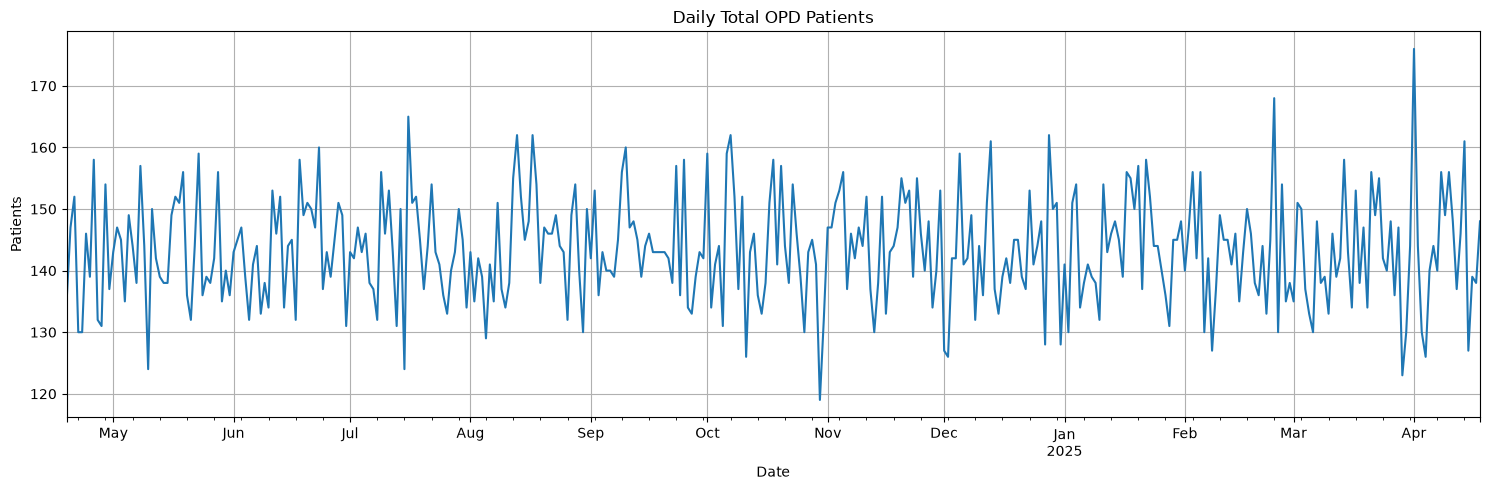

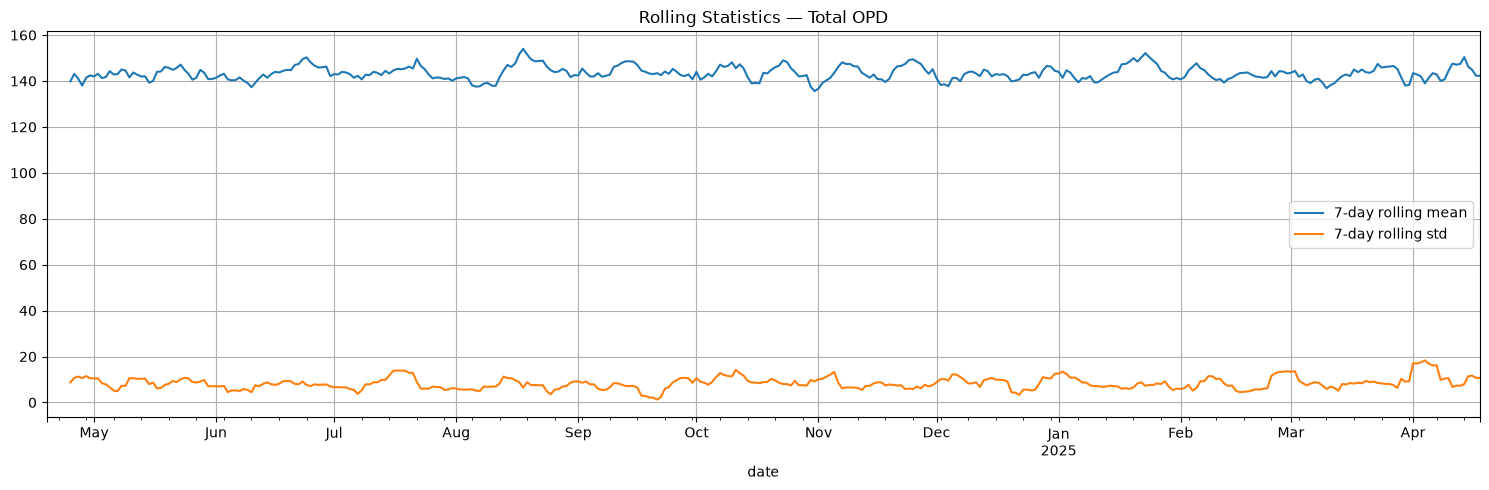

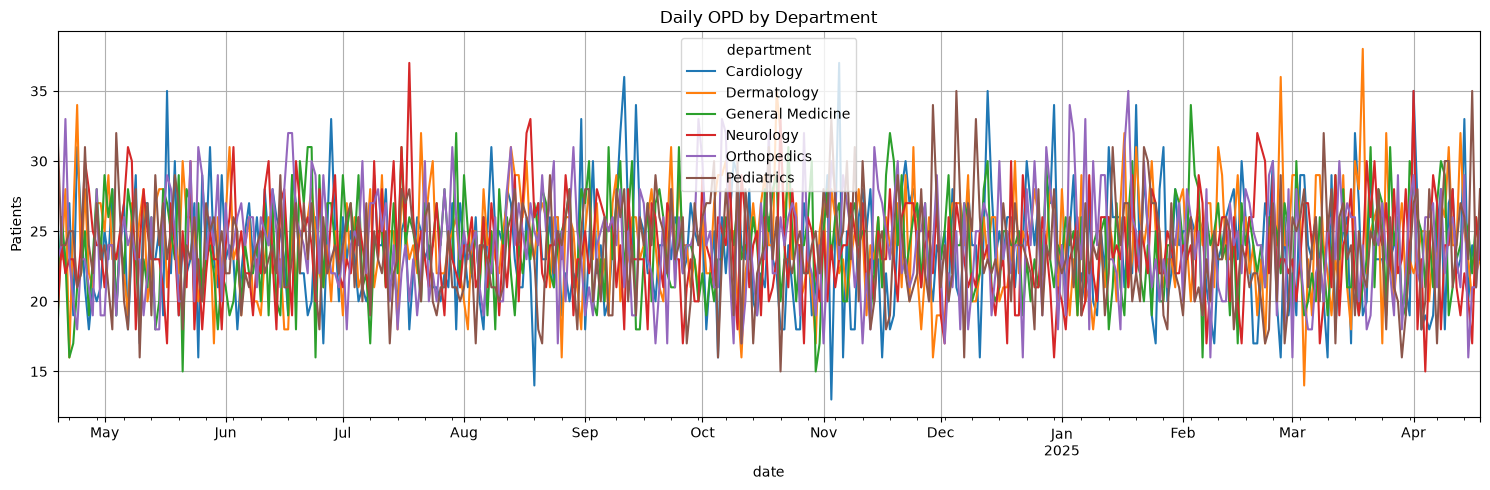

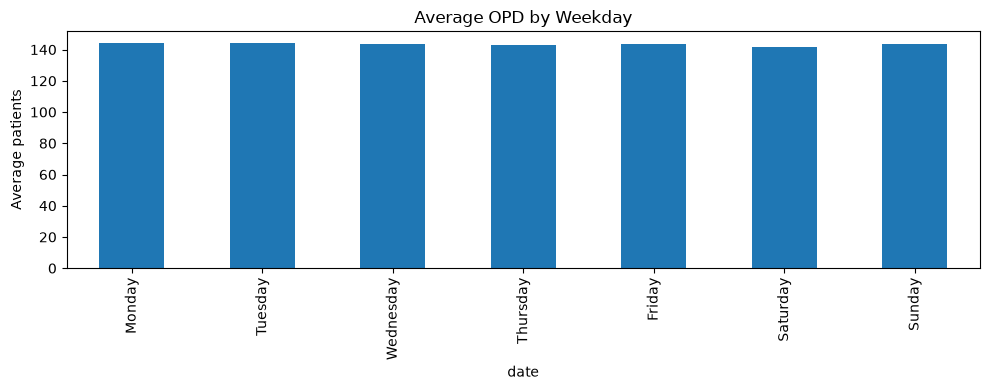

,average_patients
date,
Monday,144.461538
Tuesday,144.019231
Wednesday,143.423077
Thursday,143.211538
Friday,143.396226
Saturday,141.500000
Sunday,143.826923


In [24]:
plt.figure(figsize=(15,5))
daily_total.plot()
plt.title("Daily Total OPD Patients")
plt.xlabel("Date"); plt.ylabel("Patients"); plt.grid(True); plt.tight_layout()
plt.savefig(PLOT_DIR / "daily_total_trend.png", dpi=150)
plt.show()

plt.figure(figsize=(15,5))
daily_total.rolling(7).mean().plot(label="7-day rolling mean")
daily_total.rolling(7).std().plot(label="7-day rolling std")
plt.title("Rolling Statistics — Total OPD")
plt.legend(); plt.grid(True); plt.tight_layout()
plt.savefig(PLOT_DIR / "rolling_statistics.png", dpi=150)
plt.show()

plt.figure(figsize=(15,5))
daily_dept.plot(ax=plt.gca())
plt.title("Daily OPD by Department")
plt.ylabel("Patients"); plt.grid(True); plt.tight_layout()
plt.savefig(PLOT_DIR / "department_trends.png", dpi=150)
plt.show()

weekday_avg = daily_total.groupby(daily_total.index.day_name()).mean()
weekday_order = ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]
weekday_avg = weekday_avg.reindex(weekday_order)
weekday_avg.plot(kind="bar", figsize=(10,4), title="Average OPD by Weekday")
plt.ylabel("Average patients"); plt.tight_layout()
plt.savefig(PLOT_DIR / "weekday_pattern.png", dpi=150)
plt.show()

display(weekday_avg.to_frame("average_patients"))

,mean,median,std,min,max,sum
department,,,,,,
Dermatology,24.189041,24.0,3.601723,14.0,38.0,8829.0
Orthopedics,24.068493,24.0,3.821314,16.0,35.0,8785.0
General Medicine,23.898630,24.0,3.511852,15.0,34.0,8723.0
Neurology,23.780822,24.0,3.432419,15.0,37.0,8680.0
Cardiology,23.767123,24.0,4.021647,13.0,37.0,8675.0
Pediatrics,23.701370,24.0,3.617133,15.0,35.0,8651.0


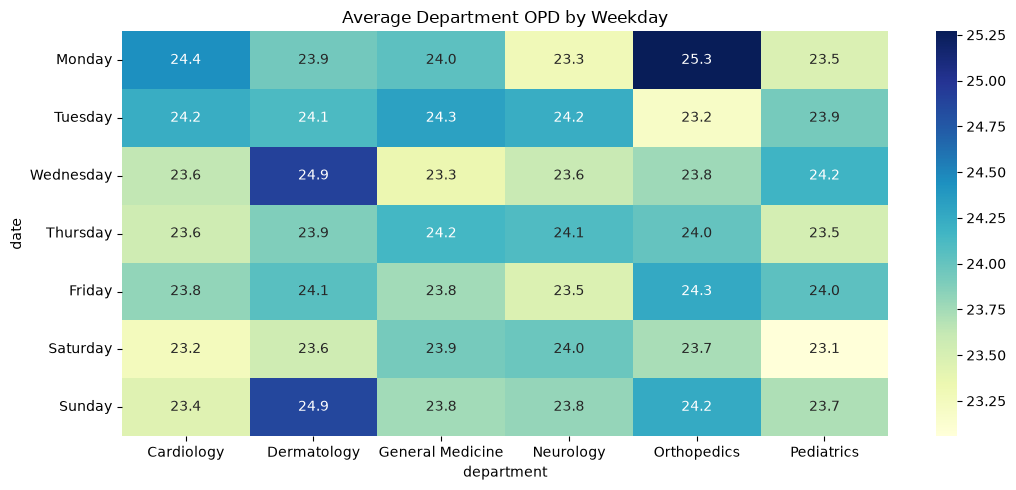

In [25]:
# Department comparison
dept_summary = daily_dept.agg(["mean", "median", "std", "min", "max", "sum"]).T
display(dept_summary.sort_values("mean", ascending=False))
dept_summary.to_csv(TABLE_DIR / "department_summary.csv")

# Weekday x department heatmap
weekday_dept = daily_dept.groupby(daily_dept.index.day_name()).mean().reindex(weekday_order)
plt.figure(figsize=(11,5))
sns.heatmap(weekday_dept, annot=True, fmt=".1f", cmap="YlGnBu")
plt.title("Average Department OPD by Weekday")
plt.tight_layout()
plt.savefig(PLOT_DIR / "weekday_department_heatmap.png", dpi=150)
plt.show()

## 7. Time-series decomposition

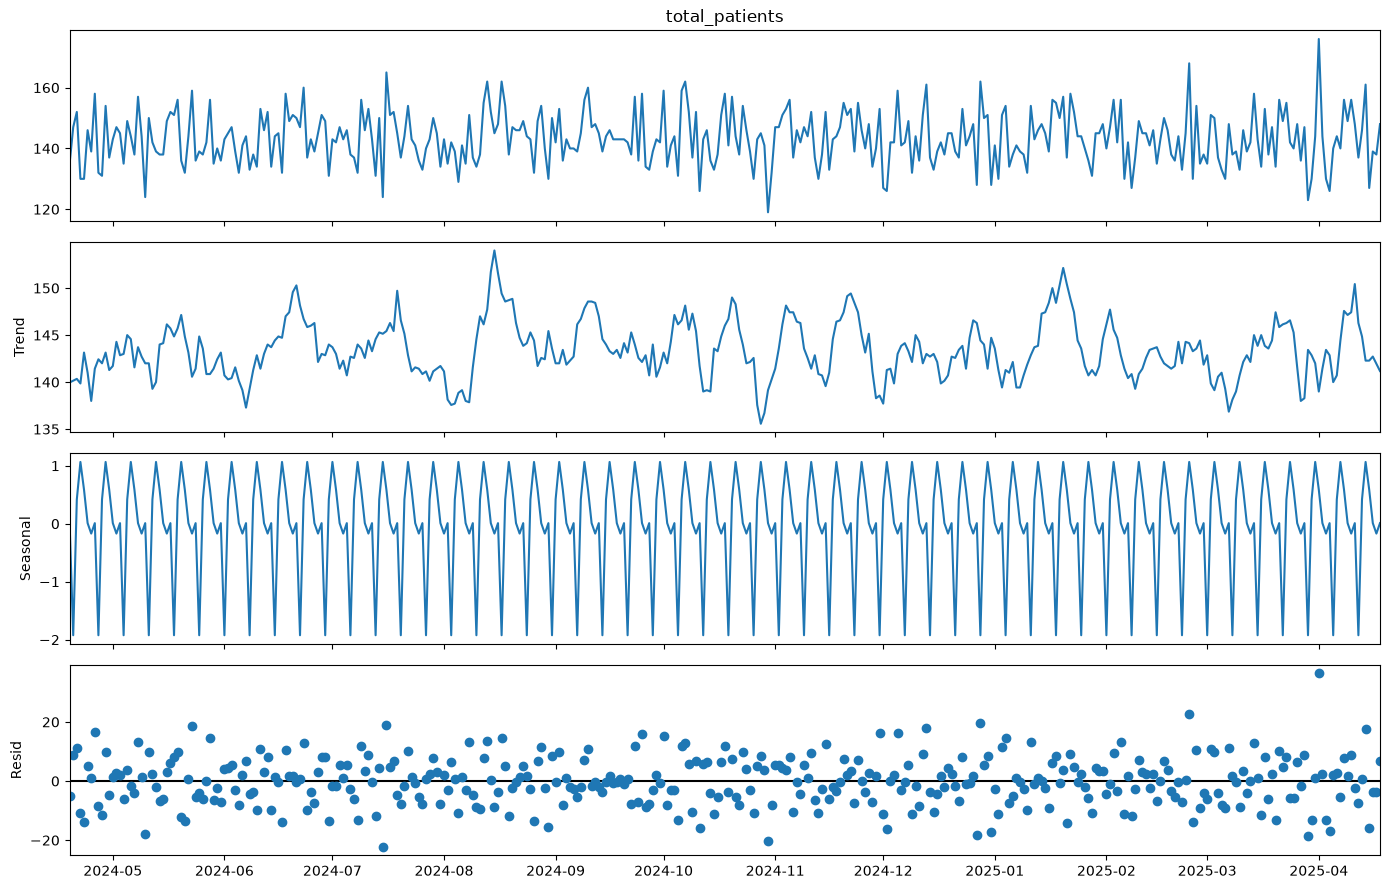

In [26]:
# Decompose the total series into trend, seasonal and residual components.
# At least two complete seasonal cycles are needed.
if len(daily_total) >= 2 * SEASONAL_PERIOD:
    decomposition = seasonal_decompose(daily_total.astype(float), model="additive",
                                       period=SEASONAL_PERIOD, extrapolate_trend="freq")
    fig = decomposition.plot()
    fig.set_size_inches(14, 9)
    plt.tight_layout()
    plt.savefig(PLOT_DIR / "total_decomposition.png", dpi=150)
    plt.show()
else:
    print("Not enough observations for decomposition.")

## 8. Stationarity: ADF, KPSS, differencing, ACF and PACF

In [27]:
def stationarity_tests(series, name="series"):
    s = pd.Series(series).dropna().astype(float)
    out = {"series": name, "n": len(s)}
    try:
        out["ADF_stat"] = adfuller(s, autolag="AIC")[0]
        out["ADF_pvalue"] = adfuller(s, autolag="AIC")[1]
    except Exception as e:
        out["ADF_error"] = str(e)
    try:
        k = kpss(s, regression="c", nlags="auto")
        out["KPSS_stat"], out["KPSS_pvalue"] = k[0], k[1]
    except Exception as e:
        out["KPSS_error"] = str(e)
    return out

stationarity_rows = []
for name, series in {"TOTAL": daily_total, **{str(c): daily_dept[c] for c in daily_dept.columns}}.items():
    stationarity_rows.append(stationarity_tests(series, name))
    stationarity_rows.append(stationarity_tests(series.diff().dropna(), name + "_diff1"))

stationarity_df = pd.DataFrame(stationarity_rows)
display(stationarity_df)
stationarity_df.to_csv(TABLE_DIR / "stationarity_tests.csv", index=False)

,series,n,ADF_stat,ADF_pvalue,KPSS_stat,KPSS_pvalue
0,TOTAL,365,-12.440731,3.758545e-23,0.044115,0.100000
1,TOTAL_diff1,364,-8.654924,4.998811e-14,0.104807,0.100000
2,Cardiology,365,-19.117013,0.000000e+00,0.064117,0.100000
3,Cardiology_diff1,364,-8.391672,2.357534e-13,0.152262,0.100000
4,Dermatology,365,-17.824621,3.150974e-30,0.069743,0.100000
5,Dermatology_diff1,364,-8.419089,2.006173e-13,0.046122,0.100000
6,General Medicine,365,-19.974712,0.000000e+00,0.141984,0.100000
7,General Medicine_diff1,364,-9.681128,1.203847e-16,0.500000,0.041667
8,Neurology,365,-18.516026,2.111603e-30,0.196795,0.100000
9,Neurology_diff1,364,-11.460435,5.571810e-21,0.174044,0.100000


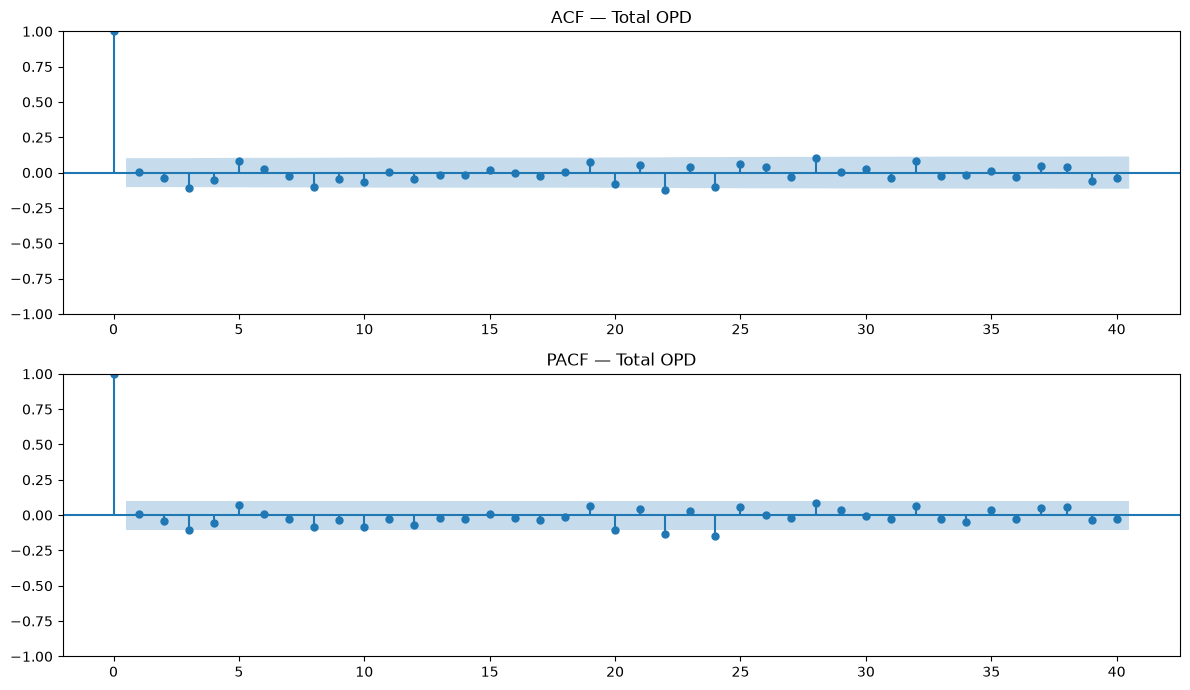

In [28]:
series_for_acf = daily_total.astype(float)
fig, axes = plt.subplots(2, 1, figsize=(12,7))
plot_acf(series_for_acf.dropna(), lags=min(40, len(series_for_acf)//2-1), ax=axes[0])
plot_pacf(series_for_acf.dropna(), lags=min(40, len(series_for_acf)//2-1), ax=axes[1], method="ywm")
axes[0].set_title("ACF — Total OPD")
axes[1].set_title("PACF — Total OPD")
plt.tight_layout()
plt.savefig(PLOT_DIR / "acf_pacf_total.png", dpi=150)
plt.show()

## 9. Train/test split and evaluation helpers

The split is chronological: the first 80% is training data and the final 20% is test data. MAPE can become misleading when actual values are zero or very small, so the function reports it only over non-zero actual values. MAE and RMSE should also be considered.

In [29]:
def chronological_split(series, test_size=TEST_SIZE):
    s = pd.Series(series).astype(float).dropna()
    split = int(len(s) * (1 - test_size))
    return s.iloc[:split], s.iloc[split:]

def calculate_metrics(actual, predicted):
    actual = pd.Series(actual).astype(float)
    predicted = pd.Series(predicted, index=actual.index).astype(float)
    valid = actual.notna() & predicted.notna()
    a, p = actual[valid], predicted[valid]
    if len(a) == 0:
        return {"MAE": np.nan, "RMSE": np.nan, "MAPE_percent": np.nan}
    mae = mean_absolute_error(a, p)
    rmse = np.sqrt(mean_squared_error(a, p))
    nonzero = a != 0
    mape = (np.mean(np.abs((a[nonzero] - p[nonzero]) / a[nonzero])) * 100
            if nonzero.any() else np.nan)
    return {"MAE": mae, "RMSE": rmse, "MAPE_percent": mape}

def seasonal_naive(train, test, period=7):
    history = train.copy()
    preds = []
    for idx in test.index:
        preds.append(history.iloc[-period] if len(history) >= period else history.iloc[-1])
        history.loc[idx] = test.loc[idx]  # one-step-ahead evaluation
    return pd.Series(preds, index=test.index)

print("Evaluation helpers ready.")

Evaluation helpers ready.


## 10. Classical models — one series

In [30]:
def fit_classical_models(series, series_name, horizon=None):
    train, test = chronological_split(series)
    rows, predictions = [], {}

    def record(model_name, pred):
        pred = pd.Series(np.asarray(pred).reshape(-1), index=test.index)
        predictions[model_name] = pred
        rows.append({"series": series_name, "model": model_name,
                     **calculate_metrics(test, pred)})

    # Baseline: last observed value
    record("Naive", np.repeat(train.iloc[-1], len(test)))
    record("SeasonalNaive_7", seasonal_naive(train, test, SEASONAL_PERIOD).values)

    # AR(p)
    try:
        p = min(7, max(1, len(train)//20))
        model = AutoReg(train, lags=p, old_names=False).fit()
        record(f"AR_{p}", model.predict(start=len(train), end=len(train)+len(test)-1))
    except Exception as e:
        print(series_name, "AR failed:", e)

    # MA(q) represented by ARIMA(0,0,q)
    try:
        model = ARIMA(train, order=(0,0,2)).fit()
        record("MA_2", model.forecast(len(test)))
    except Exception as e:
        print(series_name, "MA failed:", e)

    # ARMA(p,q)
    try:
        model = ARIMA(train, order=(2,0,2)).fit()
        record("ARMA_2_2", model.forecast(len(test)))
    except Exception as e:
        print(series_name, "ARMA failed:", e)

    # ARIMA(p,d,q)
    try:
        model = ARIMA(train, order=(2,1,2)).fit()
        record("ARIMA_2_1_2", model.forecast(len(test)))
    except Exception as e:
        print(series_name, "ARIMA failed:", e)

    # SARIMA
    try:
        model = SARIMAX(train, order=(1,1,1),
                        seasonal_order=(1,1,1,SEASONAL_PERIOD),
                        enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)
        record("SARIMA_1_1_1x1_1_1_7", model.forecast(len(test)))
    except Exception as e:
        print(series_name, "SARIMA failed:", e)

    # Holt-Winters
    try:
        model = ExponentialSmoothing(train, trend="add",
                    seasonal="add" if len(train) >= 2*SEASONAL_PERIOD else None,
                    seasonal_periods=SEASONAL_PERIOD if len(train) >= 2*SEASONAL_PERIOD else None,
                    initialization_method="estimated").fit(optimized=True)
        record("Holt_Winters", model.forecast(len(test)))
    except Exception as e:
        print(series_name, "Holt-Winters failed:", e)

    # ARIMAX/SARIMAX: without external regressors these are equivalent to ARIMA/SARIMA.
    # Add exogenous variables only after preparing aligned train/test future-known values.
    try:
        model = SARIMAX(train, order=(1,1,1),
                        enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)
        record("ARIMAX_no_exog", model.forecast(len(test)))
    except Exception as e:
        print(series_name, "ARIMAX failed:", e)

    result = pd.DataFrame(rows).sort_values("RMSE")
    return train, test, result, predictions

all_series = {"TOTAL": daily_total}
all_series.update({str(c): daily_dept[c] for c in daily_dept.columns})

metric_frames = []
model_outputs = {}
for name, series in all_series.items():
    print("\\nTraining:", name)
    train, test, metrics, preds = fit_classical_models(series, name)
    metric_frames.append(metrics)
    model_outputs[name] = {"train": train, "test": test, "predictions": preds}

classical_metrics = pd.concat(metric_frames, ignore_index=True)
display(classical_metrics.sort_values(["series", "RMSE"]))
classical_metrics.to_csv(TABLE_DIR / "classical_model_comparison.csv", index=False)

\nTraining: TOTAL
\nTraining: Cardiology
\nTraining: Dermatology
\nTraining: General Medicine
\nTraining: Neurology
\nTraining: Orthopedics
\nTraining: Pediatrics


,series,model,MAE,RMSE,MAPE_percent
9,Cardiology,AR_7,3.521195,4.291504,15.983322
10,Cardiology,MA_2,3.525381,4.299235,16.018355
11,Cardiology,ARMA_2_2,3.533585,4.303098,16.058014
12,Cardiology,ARIMA_2_1_2,3.532622,4.303238,16.056657
13,Cardiology,ARIMAX_no_exog,3.535137,4.316843,16.156137
...,...,...,...,...,...
4,TOTAL,MA_2,7.649953,9.747636,5.379399
5,TOTAL,AR_7,7.653199,9.763844,5.385866
6,TOTAL,SARIMA_1_1_1x1_1_1_7,7.834795,9.906602,5.537492
7,TOTAL,Holt_Winters,7.882038,9.961366,5.573119


### Plot actual vs predicted for the total OPD test period

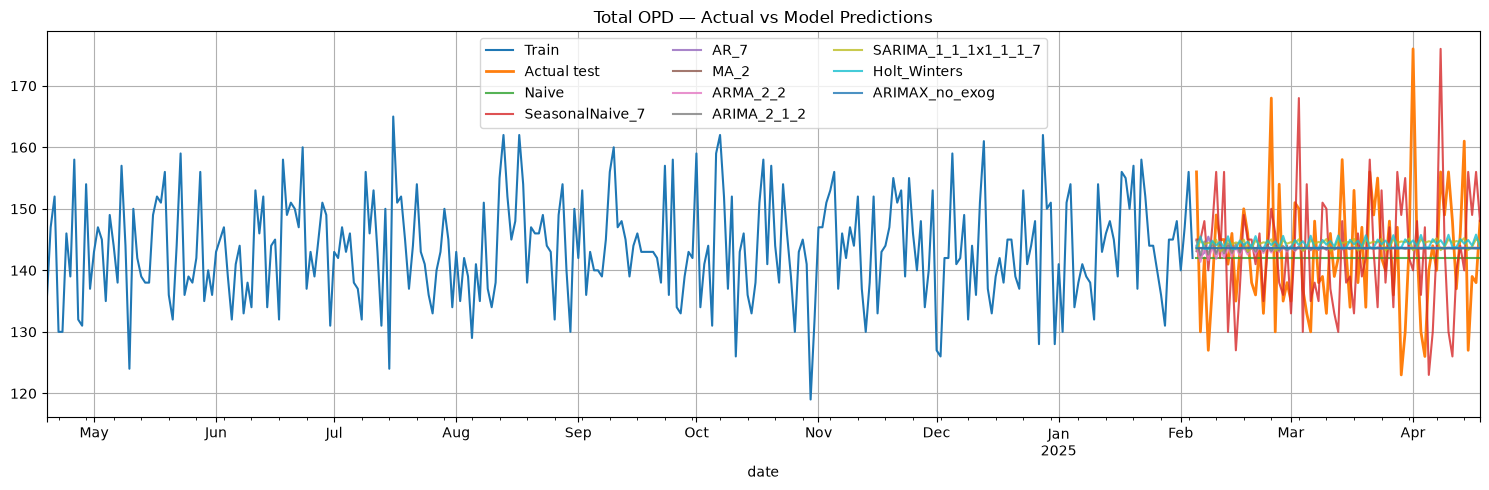

In [31]:
total_result = model_outputs["TOTAL"]
plt.figure(figsize=(15,5))
total_result["train"].plot(label="Train")
total_result["test"].plot(label="Actual test", linewidth=2)
for model_name, pred in total_result["predictions"].items():
    plt.plot(pred.index, pred.values, label=model_name, alpha=0.8)
plt.title("Total OPD — Actual vs Model Predictions")
plt.legend(ncol=3); plt.grid(True); plt.tight_layout()
plt.savefig(PLOT_DIR / "total_model_comparison.png", dpi=150)
plt.show()

## 11. VAR model across departments

In [32]:
# VAR requires a multivariate stationary input. First-difference department counts.
# This is a differenced VAR workflow (VAR on differenced series), not a full VARIMA implementation.
dept_train, dept_test = chronological_split(daily_dept)
dept_diff_train = dept_train.diff().dropna()

var_results = []
var_forecast_levels = None
try:
    var_model = VAR(dept_diff_train)
    selected = var_model.select_order(maxlags=min(14, max(1, len(dept_diff_train)//10)))
    selected_lag = selected.selected_orders.get("aic")
    if selected_lag is None or selected_lag < 1:
        selected_lag = 1
    fitted_var = var_model.fit(selected_lag)
    diff_forecast = fitted_var.forecast(dept_diff_train.values[-selected_lag:], steps=len(dept_test))
    diff_forecast = pd.DataFrame(diff_forecast, index=dept_test.index, columns=dept_test.columns)
    last_train_level = dept_train.iloc[-1]
    var_forecast_levels = diff_forecast.cumsum().add(last_train_level, axis="columns")
    for col in dept_test.columns:
        var_results.append({"series": str(col), "model": f"VAR_diff_lag{selected_lag}",
                            **calculate_metrics(dept_test[col], var_forecast_levels[col])})
    var_metrics = pd.DataFrame(var_results)
    display(var_metrics)
    var_metrics.to_csv(TABLE_DIR / "var_department_metrics.csv", index=False)
    var_forecast_levels.to_csv(FORECAST_DIR / "var_department_forecast_test.csv")
except Exception as e:
    print("VAR could not be fitted. Check number of departments, missing values and sample size.")
    print("Reason:", repr(e))

ValueError: Data must be 1-dimensional, got ndarray of shape (365, 6) instead

## 12. Forecast future values with the best classical model

In [33]:
def fit_best_and_forecast(series, horizon=FORECAST_HORIZON):
    s = pd.Series(series).astype(float).dropna()
    # Choose a robust candidate by in-sample AIC among a small set.
    candidates = []
    configs = [
        ("ARIMA_2_1_2", lambda: ARIMA(s, order=(2,1,2)).fit()),
        ("SARIMA_weekly", lambda: SARIMAX(s, order=(1,1,1),
             seasonal_order=(1,1,1,SEASONAL_PERIOD),
             enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)),
        ("Holt_Winters", lambda: ExponentialSmoothing(
             s, trend="add", seasonal="add" if len(s)>=2*SEASONAL_PERIOD else None,
             seasonal_periods=SEASONAL_PERIOD if len(s)>=2*SEASONAL_PERIOD else None,
             initialization_method="estimated").fit(optimized=True))
    ]
    for name, builder in configs:
        try:
            fitted = builder()
            candidates.append((name, fitted.aic if hasattr(fitted, "aic") else np.inf, fitted))
        except Exception as e:
            print(name, "fit failed:", e)
    if not candidates:
        raise RuntimeError("No candidate model fitted successfully.")
    best_name, best_aic, best_fit = min(candidates, key=lambda x: x[1])
    forecast = pd.Series(np.asarray(best_fit.forecast(horizon)).reshape(-1),
                         index=pd.date_range(s.index[-1] + pd.Timedelta(days=1),
                                             periods=horizon, freq="D"))
    return best_name, best_aic, forecast

future_forecasts = {}
future_summary = []
for name, series in all_series.items():
    try:
        best_name, aic, fc = fit_best_and_forecast(series)
        future_forecasts[name] = fc
        future_summary.append({"series": name, "selected_model_by_AIC": best_name, "AIC": aic})
        fc.to_frame("forecast").to_csv(FORECAST_DIR / f"{name.lower()}_future_forecast.csv")
    except Exception as e:
        print(name, "future forecast failed:", e)

display(pd.DataFrame(future_summary))
pd.DataFrame(future_summary).to_csv(TABLE_DIR / "future_model_selection.csv", index=False)

,series,selected_model_by_AIC,AIC
0,TOTAL,Holt_Winters,1592.744646
1,Cardiology,Holt_Winters,1033.270094
2,Dermatology,Holt_Winters,949.823601
3,General Medicine,Holt_Winters,934.633176
4,Neurology,Holt_Winters,917.112932
5,Orthopedics,Holt_Winters,990.428748
6,Pediatrics,Holt_Winters,955.959514


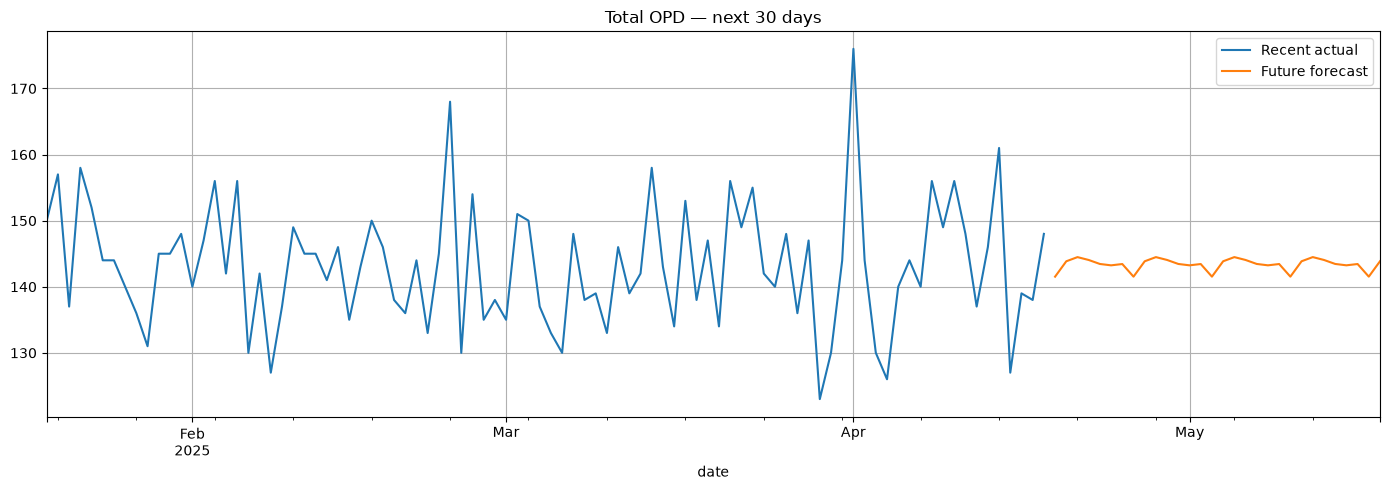

In [34]:
if "TOTAL" in future_forecasts:
    plt.figure(figsize=(14,5))
    daily_total.tail(90).plot(label="Recent actual")
    future_forecasts["TOTAL"].plot(label="Future forecast")
    plt.title(f"Total OPD — next {FORECAST_HORIZON} days")
    plt.legend(); plt.grid(True); plt.tight_layout()
    plt.savefig(PLOT_DIR / "total_future_forecast.png", dpi=150)
    plt.show()

## 13. Optional library integrations

These sections are optional because they require separate packages and may have version-specific APIs. Run only if needed. The core notebook above does not depend on these packages.

- **TSFresh**: feature extraction, not a forecasting model by itself.
- **Prophet**: univariate trend/seasonality forecasting.
- **Darts**: forecasting framework with many model choices.
- **AutoTS**: automated model search; some candidate failures are expected in broad searches. The important check is whether `fit()` finishes and `predict().forecast` contains valid finite forecasts.

In [35]:
# TSFresh optional feature extraction
if importlib.util.find_spec("tsfresh") is None:
    print("TSFresh not installed. Install with: %pip install tsfresh")
else:
    from tsfresh import extract_features
    tsfresh_input = daily_dept.reset_index().melt(id_vars="date", var_name="department", value_name="value")
    tsfresh_input["id"] = tsfresh_input["department"]
    tsfresh_input = tsfresh_input.rename(columns={"date": "time"})
    try:
        tsfresh_features = extract_features(tsfresh_input[["id","time","value"]],
                                            column_id="id", column_sort="time",
                                            disable_progressbar=True)
        display(tsfresh_features.head())
        tsfresh_features.to_csv(TABLE_DIR / "tsfresh_department_features.csv")
    except Exception as e:
        print("TSFresh extraction failed:", repr(e))

,value__variance_larger_than_standard_deviation,value__has_duplicate_max,value__has_duplicate_min,value__has_duplicate,value__sum_values,value__abs_energy,value__mean_abs_change,value__mean_change,value__mean_second_derivative_central,value__median,...,value__fourier_entropy__bins_5,value__fourier_entropy__bins_10,value__fourier_entropy__bins_100,value__permutation_entropy__dimension_3__tau_1,value__permutation_entropy__dimension_4__tau_1,value__permutation_entropy__dimension_5__tau_1,value__permutation_entropy__dimension_6__tau_1,value__permutation_entropy__dimension_7__tau_1,value__query_similarity_count__query_None__threshold_0.0,value__mean_n_absolute_max__number_of_maxima_7
Cardiology,1.0,0.0,0.0,1.0,8675.0,212067.0,4.461538,0.016484,-0.002755,24.0,...,1.225484,1.856824,3.779305,1.785684,3.135273,4.556126,5.503344,5.833122,NaN,35.142857
Dermatology,1.0,0.0,0.0,1.0,8829.0,218287.0,3.912088,0.000000,0.001377,24.0,...,1.101962,1.753347,3.813604,1.750431,3.088171,4.505976,5.437774,5.817676,NaN,34.142857
General Medicine,1.0,0.0,1.0,1.0,8723.0,212957.0,4.068681,0.013736,-0.015152,24.0,...,1.024288,1.667244,3.713941,1.782002,3.145123,4.564327,5.525747,5.806092,NaN,31.714286
Neurology,1.0,0.0,0.0,1.0,8680.0,210706.0,3.796703,0.010989,-0.011019,24.0,...,0.994957,1.625741,3.632476,1.783975,3.126400,4.537036,5.500921,5.794507,NaN,33.285714
Orthopedics,1.0,0.0,1.0,1.0,8785.0,216757.0,4.296703,0.005495,0.004132,24.0,...,0.720601,1.300292,3.312021,1.790762,3.138722,4.534312,5.549045,5.827803,NaN,33.285714


Yearly seasonality is enabled with less than 730 days (approximately 2 years) of history. The model may be under-identified, and the trend/seasonality decomposition can be unstable and dependent on the Prophet/Stan version. Consider disabling yearly seasonality or providing more history.
22:08:57 - cmdstanpy - INFO - Chain [1] start processing
22:08:58 - cmdstanpy - INFO - Chain [1] done processing


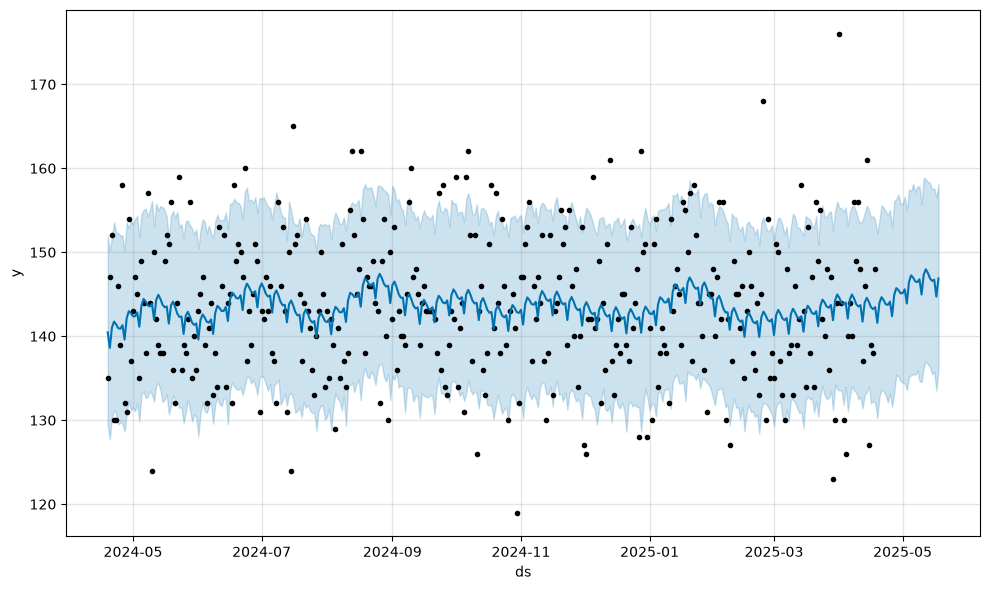

In [36]:
# Prophet optional — total OPD
if importlib.util.find_spec("prophet") is None:
    print("Prophet not installed. Install with: %pip install prophet")
else:
    from prophet import Prophet
    prophet_df = daily_total.rename_axis("ds").reset_index(name="y")
    try:
        prophet_model = Prophet(weekly_seasonality=True, yearly_seasonality=True, daily_seasonality=False)
        prophet_model.fit(prophet_df)
        future = prophet_model.make_future_dataframe(periods=FORECAST_HORIZON, freq="D")
        prophet_forecast = prophet_model.predict(future)
        prophet_forecast.tail(FORECAST_HORIZON).to_csv(FORECAST_DIR / "prophet_total_forecast.csv", index=False)
        fig = prophet_model.plot(prophet_forecast)
        plt.tight_layout(); plt.savefig(PLOT_DIR / "prophet_total_forecast.png", dpi=150); plt.show()
    except Exception as e:
        print("Prophet failed:", repr(e))

In [37]:
# Darts optional — total OPD
if importlib.util.find_spec("darts") is None:
    print("Darts not installed. Install with: %pip install 'u8darts[all]'")
else:
    try:
        from darts import TimeSeries
        from darts.models import ExponentialSmoothing as DartsExponentialSmoothing
        ts = TimeSeries.from_series(daily_total.astype(float))
        darts_model = DartsExponentialSmoothing()
        darts_model.fit(ts)
        darts_forecast = darts_model.predict(FORECAST_HORIZON)
        darts_forecast.pd_dataframe().to_csv(FORECAST_DIR / "darts_total_forecast.csv")
        display(darts_forecast.pd_dataframe().head())
    except Exception as e:
        print("Darts workflow failed:", repr(e))

Darts workflow failed: ModuleNotFoundError("No module named 'pytorch_lightning'")


In [39]:
# AutoTS optional — run independently for each series.
# For initial testing, run TOTAL only. Increase to all departments after validating.
if importlib.util.find_spec("autots") is None:
    print("AutoTS not installed. Install with: %pip install autots")
else:
    from autots import AutoTS
    autots_outputs = []
    targets_to_run = {"TOTAL": daily_total}  # change to all_series to run all 7 targets
    for name, series in targets_to_run.items():
        auto_df = series.rename("value").rename_axis("date").reset_index()
        try:
            auto_model = AutoTS(
                forecast_length=FORECAST_HORIZON,
                frequency="D",
                prediction_interval=0.90,
                ensemble=None,
                model_list="fast",
                transformer_list="fast",
                max_generations=2,
                num_validations=2,
                validation_method="backwards",
                n_jobs="auto"
            )
            auto_model = auto_model.fit(auto_df, date_col="date", value_col="value")
            auto_prediction = auto_model.predict()
            auto_forecast = auto_prediction.forecast
            if not np.isfinite(auto_forecast.to_numpy(dtype=float)).all():
                raise ValueError("AutoTS returned NaN or infinite forecast values.")
            auto_forecast.to_csv(FORECAST_DIR / f"autots_{name.lower()}_forecast.csv")
            auto_model.best_model.to_csv(TABLE_DIR / f"autots_{name.lower()}_best_model.csv", index=False)
            autots_outputs.append({"series": name, "forecast_rows": len(auto_forecast),
                                   "best_model": str(auto_model.best_model.get("Model", ["unknown"]).iloc[0])})
            print(name, "AutoTS completed.")
        except Exception as e:
            print(name, "AutoTS failed:", repr(e))
    display(pd.DataFrame(autots_outputs))

Using 9 cpus for n_jobs.
Data frequency is: D, used frequency is: D
Model Number: 1 with model AverageValueNaive in generation 0 of 2
Model Number: 2 with model AverageValueNaive in generation 0 of 2
Model Number: 3 with model AverageValueNaive in generation 0 of 2
Model Number: 4 with model DatepartRegression in generation 0 of 2
Model Number: 5 with model ETS in generation 0 of 2
Model Number: 6 with model GLM in generation 0 of 2
Model Number: 7 with model GLS in generation 0 of 2
Model Number: 8 with model LastValueNaive in generation 0 of 2
Model Number: 9 with model LastValueNaive in generation 0 of 2
Model Number: 10 with model LastValueNaive in generation 0 of 2
Model Number: 11 with model SeasonalNaive in generation 0 of 2
Model Number: 12 with model SeasonalNaive in generation 0 of 2
Model Number: 13 with model VAR in generation 0 of 2
Template Eval Error: ValueError('Only gave one variable to VAR') in model 13 in generation 0: VAR
Model Number: 14 with model ConstantNaive in

,series,forecast_rows,best_model
0,TOTAL,30,ETS


## 14. Final model comparison and best model per target

In [40]:
# Combine classical metrics and VAR metrics if available.
comparison_parts = [classical_metrics.copy()]
if "var_metrics" in globals() and isinstance(var_metrics, pd.DataFrame) and not var_metrics.empty:
    comparison_parts.append(var_metrics.copy())
final_comparison = pd.concat(comparison_parts, ignore_index=True, sort=False)
final_comparison = final_comparison.sort_values(["series", "RMSE"])
display(final_comparison)
final_comparison.to_csv(TABLE_DIR / "final_model_comparison.csv", index=False)

best_by_series = final_comparison.loc[final_comparison.groupby("series")["RMSE"].idxmin()]
display(best_by_series)
best_by_series.to_csv(TABLE_DIR / "best_model_by_series.csv", index=False)

,series,model,MAE,RMSE,MAPE_percent
9,Cardiology,AR_7,3.521195,4.291504,15.983322
10,Cardiology,MA_2,3.525381,4.299235,16.018355
11,Cardiology,ARMA_2_2,3.533585,4.303098,16.058014
12,Cardiology,ARIMA_2_1_2,3.532622,4.303238,16.056657
13,Cardiology,ARIMAX_no_exog,3.535137,4.316843,16.156137
...,...,...,...,...,...
4,TOTAL,MA_2,7.649953,9.747636,5.379399
5,TOTAL,AR_7,7.653199,9.763844,5.385866
6,TOTAL,SARIMA_1_1_1x1_1_1_7,7.834795,9.906602,5.537492
7,TOTAL,Holt_Winters,7.882038,9.961366,5.573119


,series,model,MAE,RMSE,MAPE_percent
9,Cardiology,AR_7,3.521195,4.291504,15.983322
18,Dermatology,Naive,3.205479,4.187391,13.726113
27,General Medicine,ARMA_2_2,2.836824,3.442726,12.347422
36,Neurology,AR_7,3.214950,3.993882,13.987257
45,Orthopedics,Naive,3.150685,3.697463,13.846712
54,Pediatrics,ARMA_2_2,3.171522,3.902832,14.360847
0,TOTAL,ARMA_2_2,7.636365,9.690973,5.362920


## 15. Export a compact project report

In [41]:
report_lines = [
    "# Hospital OPD Time Series Analysis — Run Summary",
    f"- Data rows after cleaning: {len(df)}",
    f"- Daily observations: {len(daily_total)}",
    f"- Date range: {daily_total.index.min().date()} to {daily_total.index.max().date()}",
    f"- Departments: {', '.join(map(str, daily_dept.columns))}",
    f"- Forecast horizon: {FORECAST_HORIZON} days",
    "",
    "## Best classical/VAR model by RMSE",
]
for _, row in best_by_series.iterrows():
    report_lines.append(
        f"- {row['series']}: {row['model']} | MAE={row['MAE']:.3f} | "
        f"RMSE={row['RMSE']:.3f} | MAPE={row['MAPE_percent']:.3f}%"
    )
(OUTPUT_DIR / "run_summary.md").write_text("\n".join(report_lines), encoding="utf-8")
print("Saved outputs to:", OUTPUT_DIR.resolve())
print("Summary:", (OUTPUT_DIR / "run_summary.md").resolve())

Saved outputs to: C:\Users\YASH BANSAL\TSA_PROJECT\outputs
Summary: C:\Users\YASH BANSAL\TSA_PROJECT\outputs\run_summary.md


## 16. Checklist before submitting

- [ ] Confirm the configured date, department and count columns match the dataset.
- [ ] Confirm whether each row is one patient or whether a count column should be summed.
- [ ] Confirm whether a missing date means zero patients or missing/unavailable data.
- [ ] Review duplicate records; do not remove them without understanding their meaning.
- [ ] Verify daily total equals the sum of department totals.
- [ ] Keep train/test split chronological and report the test period.
- [ ] Compare models using MAE, RMSE and MAPE together; inspect plots and residuals.
- [ ] Do not call ARIMAX/SARIMAX a true exogenous model unless real exogenous variables are supplied.
- [ ] Describe the department VAR workflow as differenced VAR unless you implement a full VARIMA procedure.
- [ ] Report optional-library runs only if they actually completed and produced valid forecasts.

**Interpretation note:** the best model by one metric is not automatically the best operational model. Check forecast shape, residual patterns, stability and whether the predictions make practical sense for hospital planning.

In [42]:
!git --version

git version 2.54.0.windows.1


In [43]:
!git config --global user.name "yashbansal26"
!git config --global user.email "yashbansal26122005@gmail.com"

In [ ]:
%cd "D:/"